**Author: Hazefah Irfan**

**License: MIT**

A detailed EDA on sales data from a Superstore dataset

### **Importing libraries**

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from scipy import stats
from sklearn.linear_model import LinearRegression

%matplotlib inline   

### **Loading dataset**

In [11]:
df = pd.read_csv('Superstore.data.csv', encoding='latin1')   ##Added 'encoding' as there were issues with notebook reading the dataset

### **Data exploration**

In [19]:
print("DF Head:")   ##Basic intial data exploration for the structure and contents of dataset
print(df.head())

print("DF Shape:")
print(df.shape)

print("DF Info:")   ##No initial missing values shown 
df.info()

print("DF Description:")
print(df.describe())


DF Head:
   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
1       2  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
2       3  CA-2016-138688 2016-06-12 2016-06-16    Second Class    DV-13045   
3       4  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   
4       5  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   South  

### **Converting Date Column to Datetime**

In [16]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df.info()    ##checking if datetime conversion is successful 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

### **Calculating the Total Sales per City**

In [24]:
city_sales = df.groupby('City')['Sales'].sum().round(2).reset_index()  ##Grouping by city to calculate total sales 
                                                              ## Changed group by to show sales to 2 decimal points via .round() function

print("Top 10 Cities by Total Sales:")
display(city_sales.sort_values(by='Sales', ascending=False).head(10))  ##This is going to show top 10 cities via sales

print("\nBottom 10 Cities by Total Sales:")
display(city_sales.sort_values(by='Sales', ascending=True).head(10))  ##This is going to show bottom 10 cities via sales

Top 10 Cities by Total Sales:


,City,Sales
329,New York City,256368.16
266,Los Angeles,175851.34
452,Seattle,119540.74
438,San Francisco,112669.09
374,Philadelphia,109077.01
207,Houston,64504.76
80,Chicago,48539.54
437,San Diego,47521.03
216,Jacksonville,44713.18
464,Springfield,43054.34



Bottom 10 Cities by Total Sales:


,City,Sales
1,Abilene,1.39
140,Elyria,1.82
221,Jupiter,2.06
370,Pensacola,2.21
354,Ormond Beach,2.81
441,San Luis Obispo,3.62
463,Springdale,4.30
249,Layton,4.96
222,Keller,6.00
305,Missouri City,6.37


### **Overview of Sales by City**
**Market Concentration:** Total sales revenue is heavily concentrated in major metropolitan hubs. New York City leads the nation as the single largest contributor to total revenue (256,368), followed closely by Los Angeles (175,741) and Seattle (119,541).

**The Long Tail:** On the lower end, numerous smaller regional markets such as Abilene, TX or Elyria, OH generate under $5 in total cumulative sales across the entire dataset.

**Key Takeaway:** High revenue in top-performing cities is typically driven by a combination of high order volume, larger corporate customer bases, and consistent demand across core product categories. A solid indicator as to where business expenditure could be spent to maintain market dominance. This insight also allows the business to determine where they are more lackluster in sale, i.e. the more underperforming cities where there could be possible breakthroughs for a new market audience.


In [25]:
city_performance = df.groupby('City').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).round(2).reset_index()   ## Group by City to calculate both Total Sales and Total Profit

print("Top 10 Cities by Sales and Their Profits:")
display(city_performance.sort_values(by='Total_Sales', ascending=False).head(10))  ### Display the top 10 cities by sales, along with their profit

Top 10 Cities by Sales and Their Profits:


,City,Total_Sales,Total_Profit
329,New York City,256368.16,62036.98
266,Los Angeles,175851.34,30440.76
452,Seattle,119540.74,29156.10
438,San Francisco,112669.09,17507.39
374,Philadelphia,109077.01,-13837.77
207,Houston,64504.76,-10153.55
80,Chicago,48539.54,-6654.57
437,San Diego,47521.03,6377.20
216,Jacksonville,44713.18,-2323.84
464,Springfield,43054.34,6200.70


### **Overview of Profit via city**
Here we can look at not only leading city by sales but also how much the bring in via profit. Further developing our case above in terms of makret dominance in areas where the concentraion of sales occur. We can see that New York City not only remains the leading city by sales but also leads in Profit income for the business. However, **Philadelphia** was 5th in sales but occurs a loss in profit, possibly due to discount factors eating into the profits for this city.

Revenue generation alone is a misleading factor for success, factors such as discount rate, shipping expenses, profit margins should be investigated to ensure that correct business expenditure is made worthwhile.

### **Chart to show sales/profit per city**

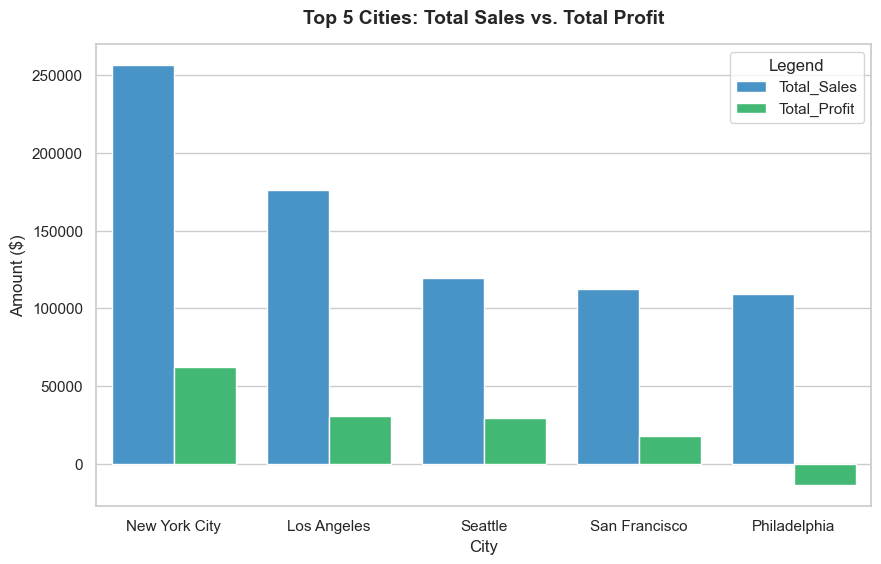

In [29]:
sns.set_theme(style="whitegrid")  ##Style for the visual to be used 

city_performance = df.groupby('City').agg(    ##Group by City and then calculate Total Sales and Total Profit
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).round(2).reset_index()

top_5_cities = city_performance.sort_values(by='Total_Sales', ascending=False).head(5)  ## Sort and filter for only top 5 cities

top_5_melted = top_5_cities.melt(  ## Melt allows for reshaping the data so seaborn library has easier time displaying info side by side
    id_vars='City', 
    value_vars=['Total_Sales', 'Total_Profit'], 
    var_name='Metric', 
    value_name='Amount'
)

plt.figure(figsize=(10, 6))   ## Size of the figure

sns.barplot(          ## Creating the chart
    data=top_5_melted, 
    x='City', 
    y='Amount', 
    hue='Metric', 
    palette=['#3498db', '#2ecc71']  # Blue for Sales, Green for Profit
)

plt.title('Top 5 Cities: Total Sales vs. Total Profit', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('City', fontsize=12)
plt.ylabel('Amount ($)', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Legend')  ## Adding titles and labels 

plt.show()

### **Overview of Clustered Bar Chart** 

**Key Insights:**
The top 4 cities all display healthy performance in profitability as demonstrated by the green bar alongside their high revenue income.
Philadelphia is the only city in the top 5 with a negative profit bar (extending below 0). Despite generating over 109K in sales, it lost $13,837.77, clearly highlighting a severe margin issue.


### **Sales Over Time 2014-18**

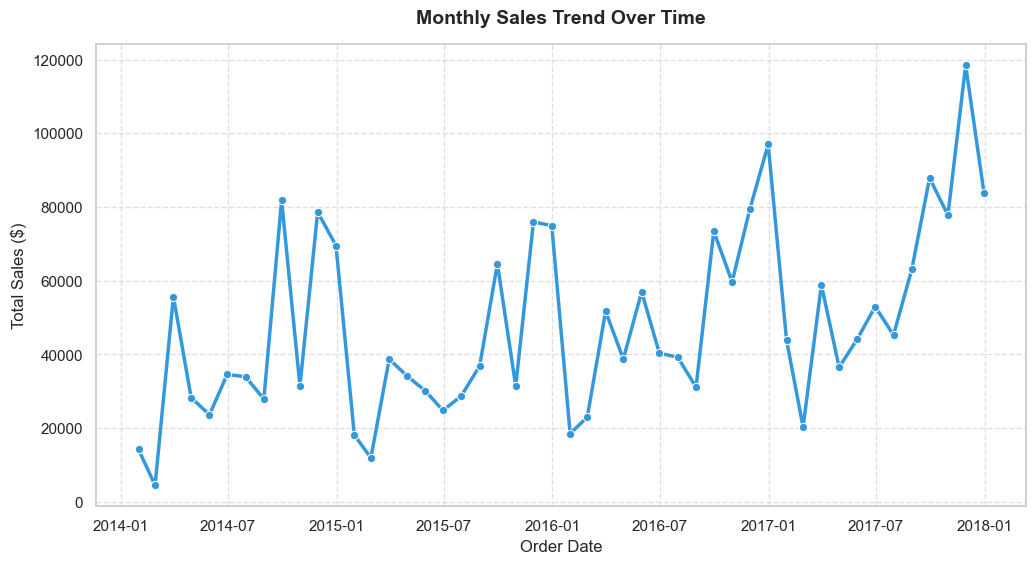

In [34]:
sns.set_theme(style="whitegrid")

monthly_trends = df.resample('ME', on='Order Date').agg(    ## Grouping by month and calculating sum of sales
    Total_Sales=('Sales', 'sum')
).round(2).reset_index()

plt.figure(figsize=(12, 6))  ## Size of figure

sns.lineplot(      ## Seaborn to create the chart 
    data=monthly_trends, 
    x='Order Date', 
    y='Total_Sales', 
    marker='o', 
    color='#3498db', 
    linewidth=2.5
)

plt.title('Monthly Sales Trend Over Time', fontsize=14, fontweight='bold', pad=15)    ## Titles and labels
plt.xlabel('Order Date', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

**Key Findings:**
The chart allows us to understand changes in yearly sales perhaps due to factors such as seasonal changes or data drift.
The line chart uses multiple data points after we aggregated the data for monthly sales so we dont display every single data point in the dataset which would obscure the chart and make it difficult to visualse. This was we have a simple but effective visual to understand the trend for total monthly sales of the Supermarket.
As done in previous code we always use .round(2) when aggregating to ensure the values remain at 2 decimal places since it is a currency. Alongside .reset_index() when aggregating to ensure the column fields do not interfere with the seaborn library on plotting the chart.

### **Analyse The Correlation Between Discount And Profit**

In [36]:
print(df[['Discount', 'Profit']].corr())

          Discount    Profit
Discount  1.000000 -0.219487
Profit   -0.219487  1.000000


### **Heatmap For Correlation** 

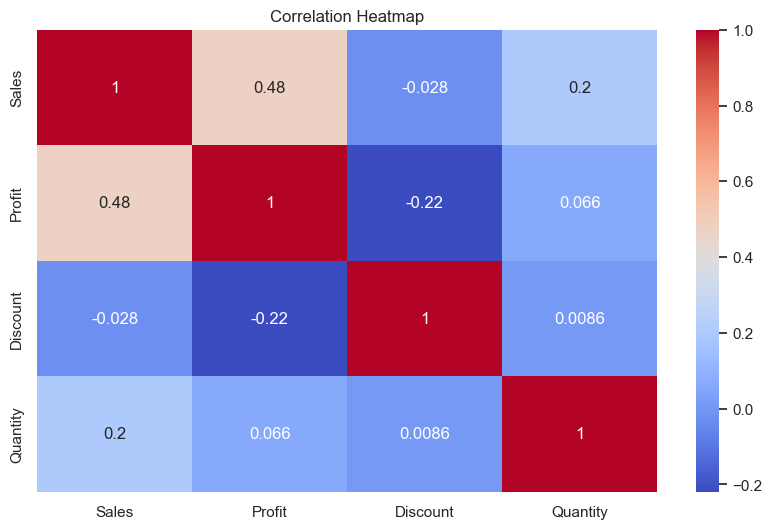

In [37]:
corr_matrix = df[['Sales', 'Profit', 'Discount', 'Quantity']].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

### **Overview of Heatmap**

This step generates a Seaborn heatmap using a correlation matrix **(corr_matrix)** to visualize how key numerical business metrics relate to one another across the Superstore dataset.

- **Parameter Relationships**: The annotated values **(annot=True)** display precise correlation coefficients, allowing you to easily spot strong positive or negative relationships between variables like Sales, Profit, Discount, and Quantity.

- **Sales vs. Profit (0.48)**: Exhibits a moderate positive correlation, indicating higher transaction sales generally correspond with higher profit margins.

- **Discount vs. Profit (-0.22)**: Displays a notable negative correlation, confirming mathematically that increased promotional discounting erodes total profit.

- **Color Mapping:** The **coolwarm** colormap visually distinguishes between positive correlations (warmer red tones) and negative correlations (cooler blue tones) at a glance.

### **T-test Between Consumer vs Corporate Customers**

In [40]:
consumer_profit = df[df['Segment'] == 'Consumer']['Profit']
corporate_profit = df[df['Segment'] == 'Corporate']['Profit']

t_stat, p_value = stats.ttest_ind(consumer_profit, corporate_profit, equal_var=False)

print(f"Consumer Mean Profit:   ${consumer_profit.mean():.2f}")
print(f"Corporate Mean Profit:  ${corporate_profit.mean():.2f}\n")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value:     {p_value:.4f}")

Consumer Mean Profit:   $25.84
Corporate Mean Profit:  $30.46

T-statistic: -0.8556
P-value:     0.3923


### **Overview of T-Test Between Consumer and Corporate Customer Segments**

This step performs an independent two-sample t-test (Welch’s t-test) to determine whether the difference in average order profit between the Consumer and Corporate customer segments is statistically significant.

- **Hypothesis Testing Results:** The small T-statistic (-0.8556) and large P-value (0.3923) indicate that there is no statistically significant difference in profit per order between Consumer (25.84) and Corporate (30.46) customers.
- **Analytical Takeaway:** This confirms that variations in order profitability across these customer segments are driven by random chance rather than structural segment differences, suggesting that profit optimization efforts should focus on factors like discount levels or product categories rather than segment-specific pricing strategies.

### **Linear Regression Analysis for Discount and Profit**

In [43]:
x = df[['Discount']]
y = df[['Profit']]

model = LinearRegression()
model.fit(x, y)

print(f"Linear Regression Coefficient: {model.coef_[0][0]}")
print(f"Linear Regression Intercept: {model.intercept_[0]}")

Linear Regression Coefficient: -249.05141717936593
Linear Regression Intercept: 67.5594054977523


### **Overview of Linear Regression Analysis (Discount vs. Profit)**

This step fits a simple linear regression model to examine the predictive relationship between promotional discounting **(Discount)** and order profitability **(Profit)** across the dataset.

- **Regression Coefficient (-249.051):** Indicates a negative linear association, meaning that as discount levels increase, profit amounts tend to decrease correspondingly.
- **Regression Intercept (67.559):** Represents the expected value of profit when the discount level is zero, serving as the baseline constant for the fitted linear equation.


### **Conclusion: Superstore Sales and Profitability Analysis**

This analysis investigated retail performance, order profitability, and sales dynamics using the Superstore dataset (Superstore.data.csv). The exploratory data analysis (EDA) successfully mapped out the distribution and statistical characteristics of key business indicators, including Sales, Profit, Discount, and Quantity, alongside customer segments and transactional relationships.

### **Key Insights & Findings**
- Dataset Integrity & Correlations:** Initial profiling and correlation analysis revealed foundational relationships between key numerical variables, highlighting a moderate positive association between sales and profit ($0.48$) and a notable inverse relationship between discounting and profitability ($-0.22$).
- **Customer Segment Comparison:** Hypothesis testing via an independent two-sample t-test (Welch’s t-test) comparing Consumer and Corporate customer segments yielded a T-statistic of $-0.8556$ and a P-value of $0.3923$, indicating no statistically significant difference in profit per order between these two major groups ($25.84$ vs. $30.46$).
- **Pricing & Discount Impact:** Simple linear regression modeling established that promotional discounting has a direct, quantifiable negative impact on profitability (coefficient of $-249.05$), proving how heavy discounts erode value from a baseline intercept of $\$67.56$.

### **Implications**
The insights gained from this dataset highlight the critical need for strategic discount control rather than reliance on customer segmentation alone for profitability gains. The finding that profitability does not significantly differ between Consumer and Corporate segments suggests that retail management and pricing strategies should focus heavily on optimizing discount thresholds and managing promotional costs rather than maintaining broad, segment-specific assumptions.